In [1]:
%load_ext autoreload
%autoreload 2
from mom6_bathy.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from pathlib import Path
from CrocoDash.case import Case

In [2]:
# CESM case (experiment) name
casename = "sauron.nwa.3"

# CESM source root (Update this path accordingly!!!)
cesmroot ="/glade/u/home/manishrv/work/installs/CROCESM_workshop_2025"

# Place where all your input files go 
inputdir = Path.home()/"scratch" / "croc_input" / casename
    
# CESM case directory
caseroot = Path.home() / "croc_cases" / casename
grid_path = "/glade/derecho/scratch/manishrv/croc_input/nwa.glofas.5/ocnice/ocean_hgrid_nwa_glofas_4_837e14.nc"
bathymetry_path = "/glade/derecho/scratch/manishrv/croc_input/nwa.glofas.5/ocnice/ocean_topog_nwa_glofas_4_837e14.nc"
vgrid_path = "/glade/derecho/scratch/manishrv/croc_input/nwa.glofas.5/ocnice/ocean_vgrid_nwa_glofas_4_837e14.nc"
compset = "CR1850MARBL_JRA"

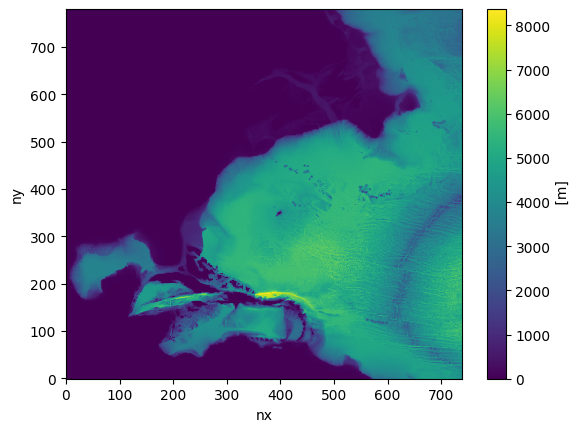

In [3]:
grid = Grid.from_supergrid(grid_path)
topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 9.5,
)
topo.depth.plot()
vgrid = VGrid.from_file(vgrid_path)

In [4]:

case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'NCGD0011',
    override = True,
    machine = "derecho",
    compset = compset
)

INFO:  csp_solver:CspSolver initialized.


Creating case...

• Updating ccs_config/modelgrid_aliases_nuopc.xml file to include the new resolution "sauron.nwa.3" consisting of the following component grids.
 atm grid: "TL319", lnd grid: "TL319", ocn grid: "ocean_hgrid_nwa_glofas_4_837e14".

• Updating ccs_config/component_grids_nuopc.xml file to include newly generated ocean grid "ocean_hgrid_nwa_glofas_4_837e14" with the following properties:
 nx: 740, ny: 780. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/sauron.nwa.3/ocnice/ESMF_mesh_ocean_hgrid_nwa_glofas_4_837e14_d420dd.nc.

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/CROCESM_workshop_2025/cime/scripts/create_newcase --compset CR1850MARBL_JRA --res sauron.nwa.3 --case /glade/u/home/manishrv/croc_cases/sauron.nwa.3 --machine derecho --run-unsupported --project NCGD0011 --non-local 

The create_newcase command was successful.

Navigating to the case directory:

cd /glade/u/home/manishrv/croc_cases/sauron.nwa.3

App

INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/manishrv/croc_cases/sauron.nwa.3.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.

Compset longname is: 1850_DATM%JRA_SLND_SICE_MOM6%REGIONAL%MARBL-BIO_SROF_SGLC_SWAV_SESP
./xmlchange MOM6_MEMORY_MODE=dynamic_symmetric --non-local



In [ ]:
case.configure_forcings(
    date_range = ["2000-01-01 00:00:00", "2000-01-06 00:00:00"],
    function_name = "get_mom6_data", # Path to CESM OUTPUT data
    product_name = "MOM6_OUTPUT",
    marbl_ic_filepath="/glade/campaign/collections/gdex/data/d651077/cesmdata/inputdata/ocn/mom/tx0.66v1/ecosys_jan_IC_omip_latlon_1x1_180W_c231221.nc",
    too_much_data = Truem
    bondaries = ["south", "north", "east"]
)


case.process_forcings()


Extract Forcings workflow was called, please go to the extract forcings path: /glade/u/home/manishrv/scratch/croc_input/sauron.nwa.3/mom6_output/extract_forcings and run the driver script there.
Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! BGC Params
  MAX_FIELDS = 200
  MARBL_FESEDFLUX_FILE = /glade/u/home/manishrv/scratch/croc_input/sauron.nwa.3/ocnice/fesedflux_total_reduce_oxic_ocean_hgrid_nwa_glofas_4_837e14_d420dd.nc
  MARBL_FEVENTFLUX_FILE = /glade/u/home/manishrv/scratch/croc_input/sauron.nwa.3/ocnice/feventflux_5gmol_ocean_hgrid_nwa_glofas_4_837e14_d420dd.nc
  

In [6]:
case._update_forcing_variables()

Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! Open boundary conditions
  OBC_NUMBER_OF_SEGMENTS = 4
  OBC_FREESLIP_VORTICITY = False
  OBC_FREESLIP_STRAIN = False
  OBC_COMPUTED_VORTICITY = True
  OBC_COMPUTED_STRAIN = True
  OBC_ZERO_BIHARMONIC = True
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_OUT = 3.0E+04
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_IN = 3000.0
  BRUSHCUTTER_MODE = True
  OBC_SEGMENT_001 = "J=0,I=0:N,FLATHER,ORLANSKI,NUDGED,ORLANSKI_TAN,NUDGED_TAN"
  OBC_SEGMENT_001_VELOCITY_NUDGING_TIMESCALES = 0.3, 360.0
  OBC_SEGMENT_001_DATA = "U=file:forcing_obc_segment_001.nc(u

In [18]:
# SAVED WAY
# Copy the shutil forcings
old_forcing_dir = Path("/glade/derecho/scratch/manishrv/croc_input/cesm.output.marbl.1/ocnice/")
# Copy all files starting with 'forcing_'
for file in old_forcing_dir.glob("*_obc_*"):
    if file.is_file():
        shutil.copy(file, case.inputdir/"ocnice" / file.name)
for file in old_forcing_dir.glob("*_IC*"):
    if file.is_file():
        shutil.copy(file, case.inputdir/"ocnice" / file.name)